# Eksploracja danych — brakujące wartości

**Cel zajęć:** nauczyć się *znajdować* braki (także te ukryte), *diagnozować*, czy są przypadkowe, i *świadomie wybierać*, czy je usunąć, czy uzupełnić.

**Plan:**
1. Rozgrzewka na zbiorze **Titanic** — te same kroki co na wykładzie.
2. Zadanie główne: **oferty mieszkań** (`nieruchomosci.csv`) — prawdziwy bałagan.

**Zadania:** 🟢 podstawowe (obowiązkowe), 🔵 dla ambitnych.

**Jak pracować:** w Colabie wybierz *Plik → Zapisz kopię na Dysku*, wgraj plik `nieruchomosci.csv` (ikona folderu po lewej → *Prześlij*), rozwiąż zadania w miejscach `# TODO`, a gotowy notatnik umieść w swoim repozytorium na GitHubie.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

URL_TITANIC = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv("titanic.csv") if Path("titanic.csv").exists() else pd.read_csv(URL_TITANIC)

if not Path("nieruchomosci.csv").exists():
    print("⚠️ Wgraj plik nieruchomosci.csv do bieżącego katalogu (w Colabie: ikona folderu → Prześlij).")

print(titanic.shape)
titanic.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


---
# Część 1. Rozgrzewka: Titanic

| kolumna | znaczenie |
|---|---|
| `Survived` | czy pasażer przeżył (1 = tak) |
| `Pclass` | klasa biletu (1, 2, 3) |
| `Sex`, `Age` | płeć, wiek |
| `SibSp`, `Parch` | liczba rodzeństwa/małżonków oraz rodziców/dzieci na pokładzie |
| `Fare` | cena biletu (£) |
| `Cabin` | numer kabiny |
| `Embarked` | port zaokrętowania: C — Cherbourg, Q — Queenstown, S — Southampton |

### 🟢 Zadanie 1: ile jest braków?

1. Policz liczbę i odsetek braków w każdej kolumnie. Pokaż tylko kolumny, w których braki występują, posortowane malejąco.
2. Narysuj poziomy wykres słupkowy odsetka braków (`.plot.barh()`), z opisem osi.

,liczba braków,odsetek [%]
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


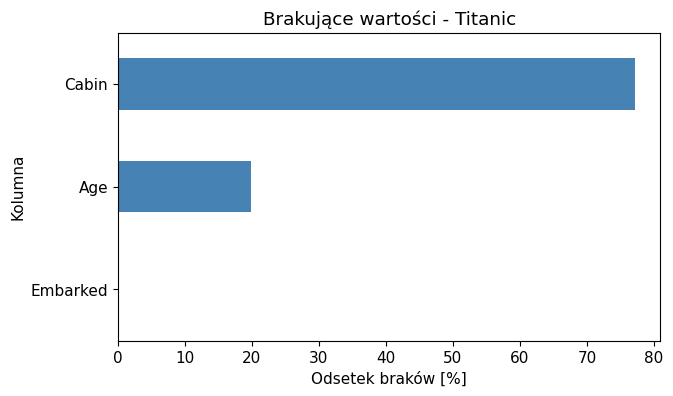

In [2]:
braki = pd.DataFrame({
    "liczba braków": titanic.isna().sum(),
    "odsetek [%]": (titanic.isna().mean() * 100).round(2),
})
braki = braki[braki["liczba braków"] > 0].sort_values("liczba braków", ascending=False)
display(braki)

ax = braki["odsetek [%]"].sort_values().plot.barh(color="steelblue")
ax.set_xlabel("Odsetek braków [%]")
ax.set_ylabel("Kolumna")
ax.set_title("Brakujące wartości - Titanic")
plt.show()

### 🟢 Zadanie 2: mapa braków

Narysuj mapę braków (`sns.heatmap(titanic.isna(), cbar=False)`) dla kolumn `Age`, `Cabin`, `Embarked` — najpierw z wierszami w oryginalnej kolejności, a potem **posortowanymi według klasy** (`Pclass`). Dwa wykresy obok siebie.

Co widać na drugim wykresie, czego nie było widać na pierwszym?

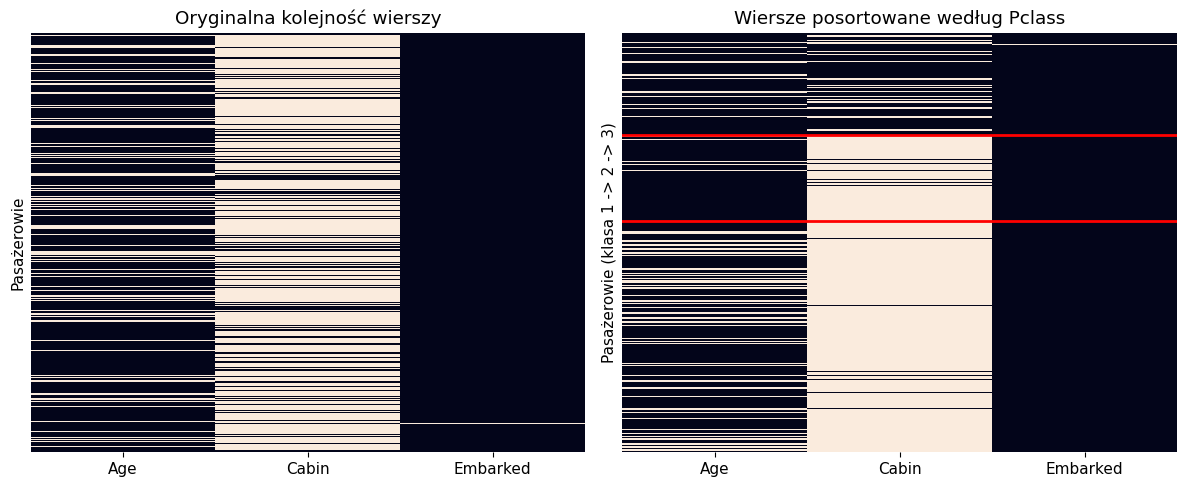

,Age,Cabin,Embarked
Pclass,,,
1,13.9,18.5,0.9
2,6.0,91.3,0.0
3,27.7,97.6,0.0


In [3]:
kolumny = ["Age", "Cabin", "Embarked"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(titanic[kolumny].isna(), cbar=False, yticklabels=False, ax=axes[0])
axes[0].set_title("Oryginalna kolejność wierszy")
axes[0].set_ylabel("Pasażerowie")

posortowane = titanic.sort_values("Pclass")
sns.heatmap(posortowane[kolumny].isna(), cbar=False, yticklabels=False, ax=axes[1])
axes[1].set_title("Wiersze posortowane według Pclass")
axes[1].set_ylabel("Pasażerowie (klasa 1 -> 2 -> 3)")
for granica in posortowane["Pclass"].value_counts().sort_index().cumsum()[:-1]:
    axes[1].axhline(granica, color="red", linewidth=2)

plt.tight_layout()
plt.show()

(titanic[kolumny].isna().groupby(titanic["Pclass"]).mean() * 100).round(1)

*Twoja odpowiedź:* Jasne pola to braki. W oryginalnej kolejności braki `Cabin` i `Age` wyglądają na rozrzucone losowo. Po posortowaniu według klasy widać wyraźny wzór: w 1. klasie numeru kabiny brakuje tylko u 18,5% pasażerów, a w 2. i 3. klasie u 91,3% i 97,6% (prawie jednolity jasny blok). Braki wieku też gęstnieją w 3. klasie (27,7% wobec 13,9% w 1. i 6,0% w 2.). Braki zależą więc od klasy, a nie są przypadkowe. `Embarked` ma tylko 2 braki (oba w 1. klasie), więc na mapie ich prawie nie widać.

### 🟢 Zadanie 3: czy braki wieku są losowe?

1. Utwórz serię `brak_wieku = titanic["Age"].isna()`.
2. Policz odsetek braków wieku w każdej klasie i osobno dla każdej płci.
3. Porównaj odsetek ocalałych wśród osób ze znanym wiekiem i bez wieku.
4. Narysuj wyniki z punktów 2 i 3 na dwóch wykresach słupkowych.
5. Czy braki wieku to MCAR? Co by się stało z odsetkiem ocalałych, gdybyśmy usunęli wiersze bez wieku?

Odsetek braków wieku wg klasy [%]:
 Pclass
1    13.9
2     6.0
3    27.7
Name: Age, dtype: float64 

Odsetek braków wieku wg płci [%]:
 Sex
female    16.9
male      21.5
Name: Age, dtype: float64 

Odsetek ocalałych [%]:
 Age
wiek znany    40.6
brak wieku    29.4
Name: Survived, dtype: float64


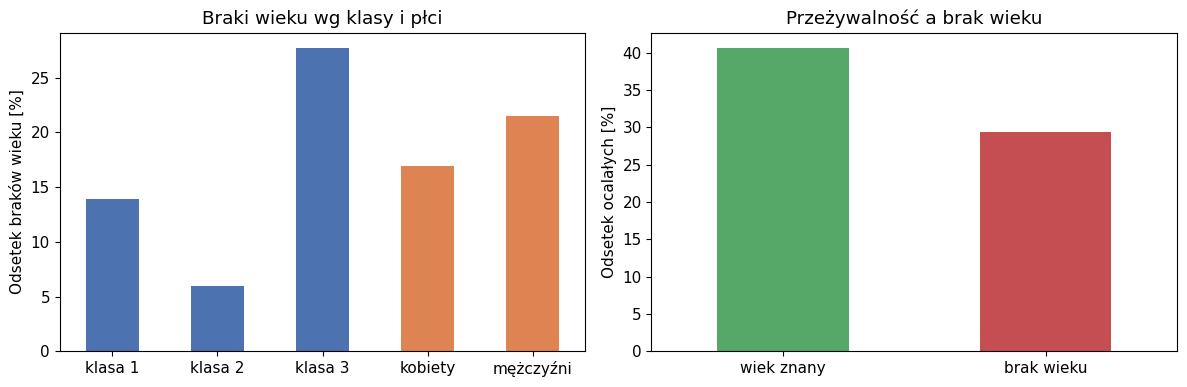

Odsetek ocalałych - cały zbiór: 38.4 %
Odsetek ocalałych - po dropna(subset=['Age']): 40.6 %


In [4]:
brak_wieku = titanic["Age"].isna()

braki_klasa = brak_wieku.groupby(titanic["Pclass"]).mean() * 100
braki_plec = brak_wieku.groupby(titanic["Sex"]).mean() * 100
print("Odsetek braków wieku wg klasy [%]:\n", braki_klasa.round(1), "\n")
print("Odsetek braków wieku wg płci [%]:\n", braki_plec.round(1), "\n")

przezycie = titanic.groupby(brak_wieku)["Survived"].mean() * 100
przezycie.index = przezycie.index.map({False: "wiek znany", True: "brak wieku"})
print("Odsetek ocalałych [%]:\n", przezycie.round(1))

braki_grupy = pd.concat([
    braki_klasa.rename(lambda k: f"klasa {k}"),
    braki_plec.rename({"female": "kobiety", "male": "mężczyźni"}),
])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
braki_grupy.plot.bar(ax=axes[0], color=["#4c72b0"] * 3 + ["#dd8452"] * 2, rot=0)
axes[0].set_ylabel("Odsetek braków wieku [%]")
axes[0].set_title("Braki wieku wg klasy i płci")

przezycie.plot.bar(ax=axes[1], color=["#55a868", "#c44e52"], rot=0)
axes[1].set_ylabel("Odsetek ocalałych [%]")
axes[1].set_xlabel("")
axes[1].set_title("Przeżywalność a brak wieku")
plt.tight_layout()
plt.show()

print("Odsetek ocalałych - cały zbiór:", round(titanic["Survived"].mean() * 100, 1), "%")
print("Odsetek ocalałych - po dropna(subset=['Age']):",
      round(titanic.dropna(subset=["Age"])["Survived"].mean() * 100, 1), "%")

*Twoja odpowiedź:* To nie jest MCAR. Wieku brakuje u 13,9% pasażerów 1. klasy, 6,0% w 2. i aż 27,7% w 3. klasie (4,6 razy częściej niż w 2.). Mężczyźni też mają trochę więcej braków (21,5%) niż kobiety (16,9%). Brak wieku wiąże się z przeżyciem: wśród osób ze znanym wiekiem przeżyło 40,6%, a wśród osób bez wieku tylko 29,4%. Braki zależą od innych, obserwowanych zmiennych (klasa, płeć), więc to raczej MAR. Gdybyśmy usunęli 177 wierszy bez wieku, odsetek ocalałych wzrósłby z 38,4% do 40,6%, czyli zawyżylibyśmy przeżywalność, bo wycinamy głównie biedniejszych pasażerów 3. klasy, którzy częściej ginęli.

### 🟢 Zadanie 4: ile kosztuje usuwanie?

Dla czterech wariantów — bez zmian, `dropna(subset=["Embarked"])`, `dropna(subset=["Age"])`, `dropna()` — zbuduj tabelę z kolumnami:
- liczba wierszy,
- odsetek ocalałych,
- odsetek pasażerów 1. klasy.

Który wariant najbardziej zniekształca dane i dlaczego?

In [5]:
warianty = {
    "bez zmian": titanic,
    'dropna(subset=["Embarked"])': titanic.dropna(subset=["Embarked"]),
    'dropna(subset=["Age"])': titanic.dropna(subset=["Age"]),
    "dropna()": titanic.dropna(),
}

tabela = pd.DataFrame({
    nazwa: {
        "liczba wierszy": len(df),
        "odsetek ocalałych [%]": round(df["Survived"].mean() * 100, 1),
        "odsetek 1. klasy [%]": round((df["Pclass"] == 1).mean() * 100, 1),
    }
    for nazwa, df in warianty.items()
}).T
tabela["liczba wierszy"] = tabela["liczba wierszy"].astype(int)
tabela

,liczba wierszy,odsetek ocalałych [%],odsetek 1. klasy [%]
bez zmian,891,38.4,24.2
"dropna(subset=[""Embarked""])",889,38.2,24.1
"dropna(subset=[""Age""])",714,40.6,26.1
dropna(),183,67.2,86.3


*Twoja odpowiedź:* Najbardziej zniekształca `dropna()`. Zostaje tylko 183 z 891 wierszy, odsetek ocalałych skacze z 38,4% do 67,2%, a udział 1. klasy z 24,2% do 86,3%. Powód: `dropna()` usuwa każdy wiersz z jakimkolwiek brakiem, a `Cabin` (77% braków) jest pusty prawie wyłącznie w 2. i 3. klasie, więc praktycznie wycinamy te klasy. Zostaje próbka bogatych pasażerów, a nie pasażerów Titanica. `dropna(subset=["Embarked"])` usuwa 2 wiersze i nic nie zmienia. `dropna(subset=["Age"])` zniekształca lekko (40,6% ocalałych, 26,1% z 1. klasy), bo braki wieku nie są losowe.

### 🟢 Zadanie 5: uzupełnianie wieku

1. **Najpierw** dodaj kolumnę-flagę `Age_brak`.
2. Utwórz dwie wersje kolumny wieku:
   - `wiek_srednia` — braki uzupełnione średnią,
   - `wiek_grupy` — braki uzupełnione medianą w grupach (klasa × płeć); wskazówka: `groupby(...)["Age"].transform("median")`.
3. Narysuj trzy histogramy obok siebie (te same przedziały, `bins=np.arange(0, 82, 2)`): znane wartości, `wiek_srednia`, `wiek_grupy`.
4. Porównaj odchylenia standardowe. Która metoda bardziej zniekształca rozkład?

Mediany wieku w grupach (klasa x płeć):
Pclass  Sex   
1       female    35.0
        male      40.0
2       female    28.0
        male      30.0
3       female    21.5
        male      25.0
Name: Age, dtype: float64 



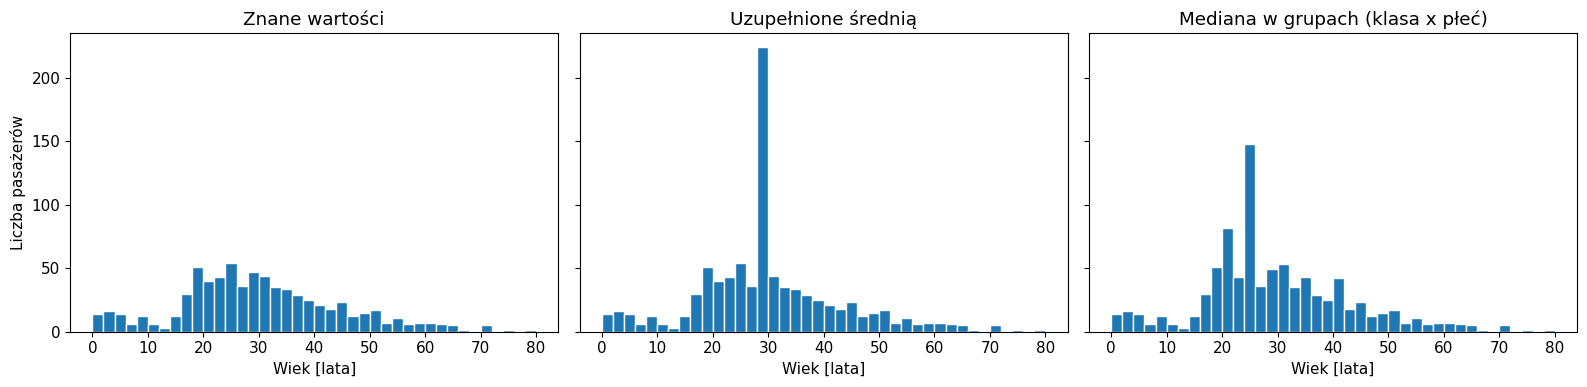

,odch. std.
Znane wartości,14.53
Uzupełnione średnią,13.00
Mediana w grupach (klasa x płeć),13.30


In [6]:
titanic["Age_brak"] = titanic["Age"].isna()

titanic["wiek_srednia"] = titanic["Age"].fillna(titanic["Age"].mean())
mediana_grupy = titanic.groupby(["Pclass", "Sex"])["Age"].transform("median")
titanic["wiek_grupy"] = titanic["Age"].fillna(mediana_grupy)

print("Mediany wieku w grupach (klasa x płeć):")
print(titanic.groupby(["Pclass", "Sex"])["Age"].median(), "\n")

wersje = {
    "Znane wartości": titanic["Age"].dropna(),
    "Uzupełnione średnią": titanic["wiek_srednia"],
    "Mediana w grupach (klasa x płeć)": titanic["wiek_grupy"],
}
bins = np.arange(0, 82, 2)
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (tytul, wiek) in zip(axes, wersje.items()):
    ax.hist(wiek, bins=bins, edgecolor="white")
    ax.set_title(tytul)
    ax.set_xlabel("Wiek [lata]")
axes[0].set_ylabel("Liczba pasażerów")
plt.tight_layout()
plt.show()

pd.Series({nazwa: wiek.std() for nazwa, wiek in wersje.items()}, name="odch. std.").round(2)

*Twoja odpowiedź:* Odchylenie standardowe znanych wartości to 14,53. Po uzupełnieniu średnią spada do 13,00, a po uzupełnieniu medianą w grupach do 13,30. Bardziej zniekształca średnia: wszystkie 177 brakujących osób dostaje ten sam wiek 29,7, więc na histogramie powstaje wysoki sztuczny "słup", a zmienność jest wyraźnie zaniżona. Mediana w grupach rozkłada braki na 6 różnych wartości (od 21,5 do 40 lat, zależnie od klasy i płci), więc słupki są mniejsze, a rozkład i odchylenie bliższe oryginałowi. Nadal jednak zaniża zmienność, bo w każdej grupie wstawia jedną stałą.

### 🔵 Zadanie 6 (dla ambitnych): imputacja modelem

Uzupełnij wiek za pomocą `IterativeImputer` z biblioteki scikit-learn, wykorzystując kolumny `Pclass`, `SibSp`, `Parch`, `Fare` oraz płeć zakodowaną jako 0/1. Porównaj histogram i odchylenie standardowe z wynikami zadania 5.

```python
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer
```

Zakres wstawionych wartości przed przycięciem: [-7.3, 42.0]


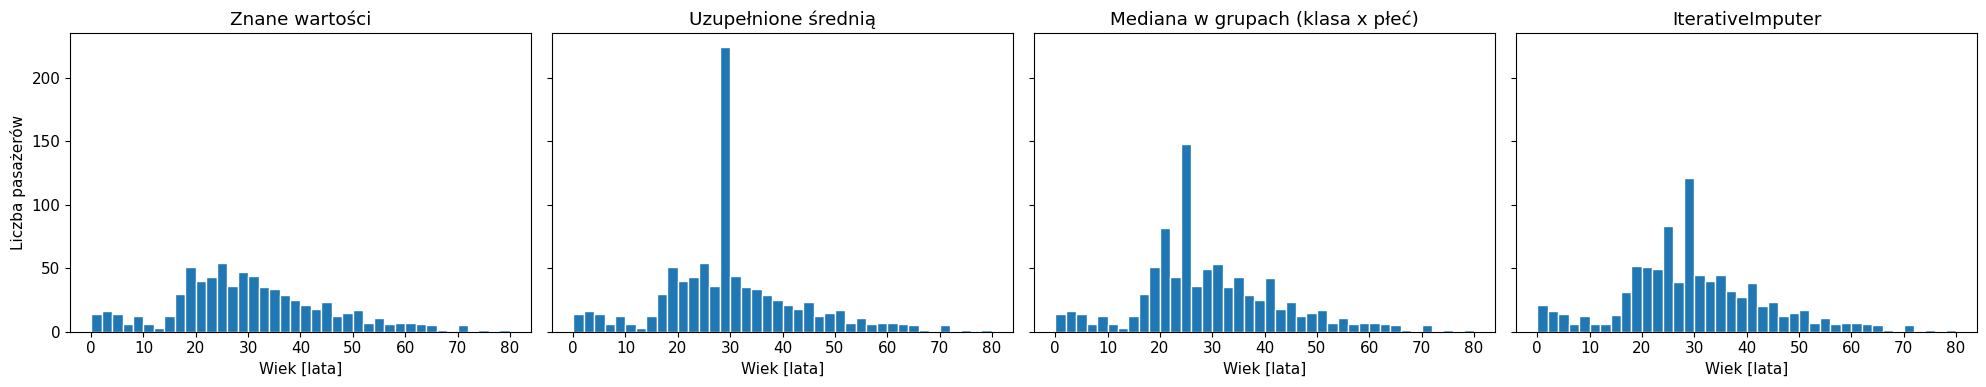

,odch. std.
Znane wartości,14.53
Uzupełnione średnią,13.00
Mediana w grupach (klasa x płeć),13.30
IterativeImputer,13.52


In [7]:
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer

X = titanic[["Age", "Pclass", "SibSp", "Parch", "Fare"]].copy()
X["Sex"] = (titanic["Sex"] == "female").astype(int)

imputer = IterativeImputer(max_iter=10, random_state=42)
titanic["wiek_model"] = imputer.fit_transform(X)[:, 0]

print("Zakres wstawionych wartości przed przycięciem:",
      titanic.loc[titanic["Age_brak"], "wiek_model"].agg(["min", "max"]).round(1).tolist())
titanic["wiek_model"] = titanic["wiek_model"].clip(lower=titanic["Age"].min())

wersje["IterativeImputer"] = titanic["wiek_model"]

fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, (tytul, wiek) in zip(axes, wersje.items()):
    ax.hist(wiek, bins=bins, edgecolor="white")
    ax.set_title(tytul)
    ax.set_xlabel("Wiek [lata]")
axes[0].set_ylabel("Liczba pasażerów")
plt.tight_layout()
plt.show()

pd.Series({nazwa: wiek.std() for nazwa, wiek in wersje.items()}, name="odch. std.").round(2)

IterativeImputer daje odchylenie 13,52, czyli najbliżej oryginału (14,53) spośród trzech metod (średnia 13,00, mediana w grupach 13,30). Wstawia ok. 96 różnych wartości zamiast jednej czy sześciu, bo korzysta z zależności wieku od klasy, płci, liczby krewnych i ceny biletu. Na histogramie wciąż widać podwyższenie w okolicy 28-30 lat (model liniowy ciągnie przewidywania do środka) i nie jest idealnie, ale rozkład jest najmniej zniekształcony. Uwaga: model przewidział kilka ujemnych wartości wieku (min. ok. -7), dlatego przyciąłem je do najmłodszego pasażera w danych (0,42 roku).

---
# Część 2. Zadanie główne: oferty mieszkań

**Dane:** plik `nieruchomosci.csv` — 45 ofert sprzedaży mieszkań w pięciu miastach.

| kolumna | znaczenie |
|---|---|
| `powierzchnia` | powierzchnia mieszkania [m²] |
| `rok_budowy` | rok budowy budynku |
| `pietro`, `liczba_pieter` | piętro mieszkania (0 = parter) i liczba pięter budynku |
| `parking`, `balkon` | Tak / Nie |
| `stan` | stan mieszkania |
| `cena_m2`, `cena_total` | cena za m² i cena całkowita [zł] |

Plik przygotował ktoś, kto różne braki zapisywał na różne sposoby. Twoim zadaniem jest je znaleźć i rozsądnie obsłużyć.

### 🟢 Zadanie 7: pierwszy rzut oka

1. Wczytaj plik bez żadnych dodatkowych parametrów i sprawdź typy kolumn (`dtypes`).
2. Policz braki (`isna().sum()`). Ile braków widzi pandas?
3. Dlaczego kolumna `powierzchnia` nie jest liczbowa, choć zawiera powierzchnię w m²?

In [8]:
mieszkania = pd.read_csv("nieruchomosci.csv")

print(mieszkania.dtypes, "\n")
print(mieszkania.isna().sum(), "\n")
print("Łącznie braków widzianych przez pandas:", mieszkania.isna().sum().sum())

id                int64
miasto           object
dzielnica        object
powierzchnia     object
liczba_pokoi      int64
rok_budowy       object
pietro           object
liczba_pieter     int64
parking          object
balkon           object
stan             object
cena_m2           int64
cena_total        int64
dtype: object 

id               0
miasto           0
dzielnica        0
powierzchnia     4
liczba_pokoi     0
rok_budowy       4
pietro           0
liczba_pieter    0
parking          0
balkon           0
stan             0
cena_m2          0
cena_total       0
dtype: int64 

Łącznie braków widzianych przez pandas: 8


*Twoja odpowiedź:* Pandas widzi tylko 8 braków: 4 w `powierzchnia` (zapisane jako `N/A`) i 4 w `rok_budowy` (zapisane jako `NA`). Te dwa napisy pandas domyślnie zamienia na NaN. Kolumna `powierzchnia` nie jest liczbowa (typ tekstowy `str`/`object`), bo oprócz liczb ma napis `"brak"`. Wystarczy jedna wartość tekstowa, żeby cała kolumna została wczytana jako tekst. Z tego samego powodu tekstowe są `rok_budowy` (`"brak"`) i `pietro` (`"brak"`).

### 🟢 Zadanie 8: braki „w przebraniu”

1. Dla każdej kolumny tekstowej i każdej kolumny liczbowej obejrzyj występujące wartości (`value_counts(dropna=False)` albo `unique()`). Wypisz wszystkie wartości, które oznaczają brak.
2. **Pułapka:** w kolumnach `powierzchnia` i `pietro` występuje `0`. Czy w obu przypadkach to brak danych?
3. Wczytaj plik ponownie z parametrem `na_values` podanym jako **słownik** (kolumna → lista wartości), tak aby każda kolumna miała tylko „swoje” oznaczenia braków.
4. Sprawdź typy kolumn i policz braki jeszcze raz.

In [9]:
for kol in mieszkania.columns.drop(["id", "dzielnica"]):
    print(f"--- {kol} ---")
    print(mieszkania[kol].value_counts(dropna=False).sort_index().to_dict(), "\n")

--- miasto ---
{'Gdańsk': 9, 'Kraków': 9, 'Poznań': 9, 'Warszawa': 9, 'Wrocław': 9} 

--- powierzchnia ---
{'0': 3, '42': 1, '45': 1, '46': 1, '48': 2, '50': 1, '51': 1, '52': 1, '54': 1, '55': 2, '56': 1, '58': 2, '60': 2, '62': 2, '64': 1, '65': 1, '66': 1, '68': 1, '69': 1, '70': 2, '72': 2, '75': 1, '76': 1, '78': 1, '80': 1, '82': 1, '85': 1, '88': 1, '90': 1, '95': 1, 'brak': 2, nan: 4} 

--- liczba_pokoi ---
{1: 4, 2: 15, 3: 18, 4: 7, 5: 1} 

--- rok_budowy ---
{'1995': 1, '1996': 1, '1997': 1, '1998': 1, '1999': 1, '2000': 1, '2001': 1, '2002': 1, '2003': 1, '2004': 1, '2005': 1, '2006': 1, '2007': 1, '2008': 1, '2009': 1, '2010': 2, '2011': 2, '2012': 1, '2013': 2, '2014': 2, '2015': 2, '2016': 2, '2017': 2, '2018': 2, '2019': 2, '2020': 2, '2021': 1, '2022': 1, 'brak': 3, nan: 4} 

--- pietro ---
{'-999': 2, '0': 3, '1': 8, '2': 9, '3': 7, '4': 6, '5': 3, '6': 3, '7': 2, '8': 1, 'brak': 1} 

--- liczba_pieter ---
{2: 2, 3: 3, 4: 7, 5: 6, 6: 4, 7: 4, 8: 5, 9: 4, 10: 4, 11: 3, 

*Twoja odpowiedź:* Wartości oznaczające brak:

| kolumna | oznaczenia braku |
|---|---|
| `powierzchnia` | `N/A` (4), `brak` (2), `0` (3) |
| `rok_budowy` | `NA` (4), `brak` (3) |
| `pietro` | `brak` (1), `-999` (2) |
| `parking` | `?` (5) |
| `balkon` | `?` (3) |
| `cena_m2` | `-1` (1), `-999` (1) |

Do tego w `stan` jest dziwna wartość `很好`, ale to błędna kategoria, a nie brak (zadanie 9).

**Pułapka z zerem:** w `powierzchnia` 0 to brak danych, bo mieszkanie nie może mieć 0 m², a te oferty mają normalną cenę całkowitą (np. 648 000 zł). W `pietro` 0 to **parter** (opis danych: "0 = parter"), czyli poprawna wartość, a nie brak. Dlatego `0` trzeba podać jako brak tylko dla `powierzchnia`, a nie globalnie. Do tego służy słownik w `na_values`.

In [10]:
braki_slownik = {
    "powierzchnia": ["brak", "0"],
    "rok_budowy": ["brak"],
    "pietro": ["brak", "-999"],
    "parking": ["?"],
    "balkon": ["?"],
    "cena_m2": ["-1", "-999"],
}

mieszkania = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)

print(mieszkania.dtypes, "\n")
print(mieszkania.isna().sum(), "\n")
print("Łącznie braków:", mieszkania.isna().sum().sum())
print("Mieszkań na parterze (pietro == 0):", (mieszkania["pietro"] == 0).sum())

id                 int64
miasto            object
dzielnica         object
powierzchnia     float64
liczba_pokoi       int64
rok_budowy       float64
pietro           float64
liczba_pieter      int64
parking           object
balkon            object
stan              object
cena_m2          float64
cena_total         int64
dtype: object 

id               0
miasto           0
dzielnica        0
powierzchnia     9
liczba_pokoi     0
rok_budowy       7
pietro           3
liczba_pieter    0
parking          5
balkon           3
stan             0
cena_m2          2
cena_total       0
dtype: int64 

Łącznie braków: 29
Mieszkań na parterze (pietro == 0): 3


### 🟢 Zadanie 9: dziwna kategoria

Obejrzyj wartości w kolumnie `stan`. Jedna z nich nie pasuje do pozostałych. Co mogła oznaczać i jak ją poprawić? Zaproponuj i zastosuj rozwiązanie (uzasadnij je).

In [11]:
print(mieszkania["stan"].value_counts(), "\n")
display(mieszkania[mieszkania["stan"] == "很好"])

mieszkania["stan"] = mieszkania["stan"].replace({"很好": "Bardzo dobry"})

print(mieszkania["stan"].value_counts(), "\n")
mieszkania.groupby("stan")[["cena_m2", "rok_budowy"]].median()

stan
Dobry           28
Bardzo dobry    11
Do remontu       5
很好               1
Name: count, dtype: int64 



,id,miasto,dzielnica,powierzchnia,liczba_pokoi,rok_budowy,pietro,liczba_pieter,parking,balkon,stan,cena_m2,cena_total
1,2,Kraków,Krowodrza,48.0,2,NaN,2.0,5,Nie,Tak,很好,10200.0,489600


stan
Dobry           28
Bardzo dobry    12
Do remontu       5
Name: count, dtype: int64 



,cena_m2,rok_budowy
stan,,
Bardzo dobry,11500.0,2019.0
Do remontu,9000.0,1997.0
Dobry,9500.0,2010.0


"很好" to po chińsku "bardzo dobrze". To błąd przy wprowadzaniu/tłumaczeniu, a nie brak danych. Odpowiada kategorii "Bardzo dobry". Pasuje do tego cena: 10 200 zł/m² to więcej niż w każdym krakowskim mieszkaniu "Dobry" (8 500-9 800 zł), a podobnie jak w krakowskich "Bardzo dobry" (9 200 i 10 500 zł).

### 🟢 Zadanie 10: mapa braków

1. Narysuj odsetek braków w kolumnach (wykres słupkowy) i mapę braków.
2. Czy braki w różnych kolumnach występują w tych samych wierszach? (Wskazówka: `mieszkania.isna().corr()` dla kolumn z brakami.)

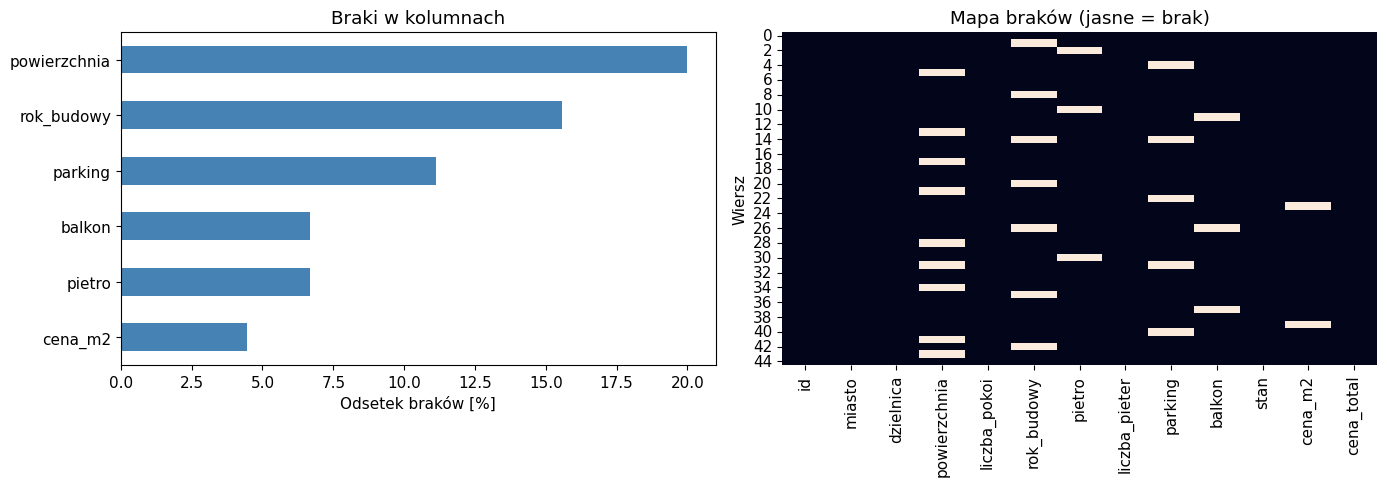

Ile braków w jednym wierszu: {0: 19, 1: 23, 2: 3}


,cena_m2,pietro,balkon,parking,rok_budowy,powierzchnia
cena_m2,1.00,-0.06,-0.06,-0.08,-0.09,-0.11
pietro,-0.06,1.00,-0.07,-0.09,-0.11,-0.13
balkon,-0.06,-0.07,1.00,-0.09,0.13,-0.13
parking,-0.08,-0.09,-0.09,1.00,0.04,-0.00
rok_budowy,-0.09,-0.11,0.13,0.04,1.00,-0.21
powierzchnia,-0.11,-0.13,-0.13,-0.00,-0.21,1.00


In [12]:
braki_m = mieszkania.isna()
odsetek = braki_m.mean() * 100
odsetek = odsetek[odsetek > 0].sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
odsetek.plot.barh(ax=axes[0], color="steelblue")
axes[0].set_xlabel("Odsetek braków [%]")
axes[0].set_title("Braki w kolumnach")

sns.heatmap(braki_m, cbar=False, ax=axes[1])
axes[1].set_title("Mapa braków (jasne = brak)")
axes[1].set_ylabel("Wiersz")
plt.tight_layout()
plt.show()

print("Ile braków w jednym wierszu:", braki_m.sum(axis=1).value_counts().sort_index().to_dict())
braki_m[odsetek.index].corr().round(2)

*Twoja odpowiedź:* Najwięcej braków ma `powierzchnia` (20%), potem `rok_budowy` (15,6%), `parking` (11,1%), `pietro` i `balkon` (6,7%) oraz `cena_m2` (4,4%). Braki w różnych kolumnach prawie nigdy nie występują w tych samych wierszach. Korelacje między flagami braków są bliskie zera (od -0,21 do 0,13), a mapa wygląda jak rozrzucone pojedyncze kreski. 19 wierszy nie ma żadnego braku, 23 mają dokładnie jeden, a tylko 3 mają dwa. Braki wyglądają na niezależne od siebie. To ważne dla zadania 11: w żadnym wierszu nie brakuje jednocześnie `powierzchnia` i `cena_m2`.

### 🟢 Zadanie 11: odtwórz, zamiast zgadywać

Sprawdź, czy dla wierszy bez braków zachodzi zależność `cena_total = powierzchnia × cena_m2`. Jeśli tak — wykorzystaj ją, żeby **odtworzyć** brakujące wartości w kolumnach `powierzchnia` i `cena_m2`. Ile braków udało się w ten sposób usunąć?

To jest „ręczne uzupełnianie” z wykładu: znamy prawdziwą wartość, więc nie musimy jej szacować.

In [13]:
pelne = mieszkania.dropna(subset=["powierzchnia", "cena_m2"])
roznica = pelne["cena_total"] - pelne["powierzchnia"] * pelne["cena_m2"]
print("Sprawdzonych wierszy:", len(pelne), "| maks. |różnica|:", roznica.abs().max())
print("cena_total == powierzchnia x cena_m2 we wszystkich?", np.allclose(roznica, 0))
print("Wierszy z brakiem w obu kolumnach naraz:",
      (mieszkania["powierzchnia"].isna() & mieszkania["cena_m2"].isna()).sum())

przed = mieszkania[["powierzchnia", "cena_m2"]].isna().sum()

mieszkania["powierzchnia"] = mieszkania["powierzchnia"].fillna(
    mieszkania["cena_total"] / mieszkania["cena_m2"])
mieszkania["cena_m2"] = mieszkania["cena_m2"].fillna(
    mieszkania["cena_total"] / mieszkania["powierzchnia"])

po = mieszkania[["powierzchnia", "cena_m2"]].isna().sum()
display(pd.DataFrame({"braki przed": przed, "braki po": po}))
print("Odtworzono wartości:", (przed - po).sum())

Sprawdzonych wierszy: 34 | maks. |różnica|: 0.0
cena_total == powierzchnia x cena_m2 we wszystkich? True
Wierszy z brakiem w obu kolumnach naraz: 0


,braki przed,braki po
powierzchnia,9,0
cena_m2,2,0


Odtworzono wartości: 11


### 🟢 Zadanie 12: pozostałe braki

Dla każdej z kolumn `rok_budowy`, `pietro`, `parking`, `balkon`:
1. **Najpierw** dodaj kolumnę-flagę braku (np. `rok_budowy_brak`).
2. Zdecyduj, co zrobić z brakami, i zaimplementuj decyzję. Do rozważenia:
   - `rok_budowy` — mediana całościowa czy mediana w grupach? Jakie grupy mają sens: `miasto` czy `stan`? Policz mediany w obu podziałach, zanim wybierzesz.
   - `pietro` — są tylko 3 braki; mediana, a może coś mądrzejszego (np. środkowe piętro budynku: `liczba_pieter // 2`)?
   - `parking`, `balkon` — dominanta czy osobna kategoria `"nieznane"`? Co się stanie z odsetkiem mieszkań z parkingiem w każdym z tych wariantów?
3. Sprawdź, że w zbiorze nie ma już braków.

In [14]:
for kol in ["rok_budowy", "pietro", "parking", "balkon"]:
    mieszkania[f"{kol}_brak"] = mieszkania[kol].isna()

print("Mediana całościowa:", mieszkania["rok_budowy"].median())
display(mieszkania.groupby("miasto")["rok_budowy"].agg(["median", "min", "max", "count"]))
display(mieszkania.groupby("stan")["rok_budowy"].agg(["median", "min", "max", "count"]))
mieszkania["rok_budowy"] = mieszkania["rok_budowy"].fillna(
    mieszkania.groupby("stan")["rok_budowy"].transform("median"))

display(mieszkania.loc[mieszkania["pietro_brak"], ["id", "liczba_pieter"]])
mieszkania["pietro"] = mieszkania["pietro"].fillna(mieszkania["liczba_pieter"] // 2)

for kol in ["parking", "balkon"]:
    tylko_znane = (mieszkania[kol].dropna() == "Tak").mean() * 100
    z_dominanta = (mieszkania[kol].fillna(mieszkania[kol].mode()[0]) == "Tak").mean() * 100
    z_nieznane = (mieszkania[kol].fillna("nieznane") == "Tak").mean() * 100
    print(f"{kol}: 'Tak' wśród znanych {tylko_znane:.1f}% | po dominancie {z_dominanta:.1f}% "
          f"| z kategorią 'nieznane' {z_nieznane:.1f}%")
for kol in ["parking", "balkon"]:
    mieszkania[kol] = mieszkania[kol].fillna("nieznane")

print("\nPozostałe braki:", mieszkania.isna().sum().sum())
assert mieszkania.isna().sum().sum() == 0

Mediana całościowa: 2011.5


,median,min,max,count
miasto,,,,
Gdańsk,2001.5,1997.0,2014.0,8
Kraków,2013.0,1995.0,2019.0,7
Poznań,2013.5,1996.0,2022.0,8
Warszawa,2015.0,2013.0,2020.0,7
Wrocław,2011.0,2006.0,2020.0,8


,median,min,max,count
stan,,,,
Bardzo dobry,2019.0,2017.0,2022.0,10
Do remontu,1997.0,1995.0,1999.0,5
Dobry,2010.0,2000.0,2016.0,23


,id,liczba_pieter
2,3,4
10,11,7
30,31,6


parking: 'Tak' wśród znanych 85.0% | po dominancie 86.7% | z kategorią 'nieznane' 75.6%
balkon: 'Tak' wśród znanych 83.3% | po dominancie 84.4% | z kategorią 'nieznane' 77.8%

Pozostałe braki: 0


### 🟢 Zadanie 13: porównaj przed i po

Wczytaj surowy plik jeszcze raz (z `na_values` z zadania 8) i porównaj z oczyszczoną wersją:
1. statystyki opisowe kolumn `powierzchnia`, `rok_budowy`, `cena_m2` (`describe()`),
2. histogram `rok_budowy` przed i po uzupełnieniu (dwa wykresy obok siebie, te same przedziały).

Czy uzupełnianie zmieniło rozkłady w istotny sposób?

powierzchnia       rok_budowy          cena_m2         
             przed    po      przed      po    przed       po
count         36.0  45.0       38.0    45.0     43.0     45.0
mean          64.6  64.9     2010.3  2010.6  10223.3  10244.3
std           13.7  12.8        7.8     7.4   1611.7   1623.9
min           42.0  42.0     1995.0  1995.0   8200.0   8200.0
25%           54.8  56.0     2004.2  2006.0   9000.0   9000.0
50%           63.0  62.0     2011.5  2011.0   9800.0   9800.0
75%           72.8  72.0     2016.8  2017.0  11100.0  11200.0
max           95.0  95.0     2022.0  2022.0  15000.0  15000.0

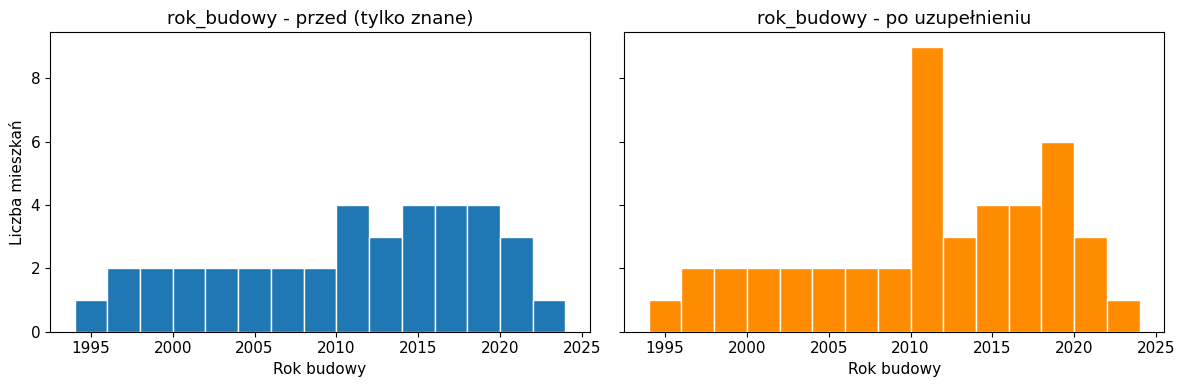

In [15]:
surowe = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)

kolumny_num = ["powierzchnia", "rok_budowy", "cena_m2"]
porownanie = pd.concat(
    {k: pd.DataFrame({"przed": surowe[k].describe(), "po": mieszkania[k].describe()})
     for k in kolumny_num},
    axis=1,
).round(1)
display(porownanie)

bins = np.arange(1994, 2025, 2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
axes[0].hist(surowe["rok_budowy"].dropna(), bins=bins, edgecolor="white")
axes[0].set_title("rok_budowy - przed (tylko znane)")
axes[1].hist(mieszkania["rok_budowy"], bins=bins, edgecolor="white", color="darkorange")
axes[1].set_title("rok_budowy - po uzupełnieniu")
for ax in axes:
    ax.set_xlabel("Rok budowy")
axes[0].set_ylabel("Liczba mieszkań")
plt.tight_layout()
plt.show()

*Twoja odpowiedź:* Nie w istotny sposób. `rok_budowy`: średnia 2010,3 -> 2010,6, mediana 2011,5 -> 2011, odchylenie 7,8 -> 7,4. Zmienność lekko spadła, bo 7 mieszkań dostało jedną z dwóch wartości (2010 dla "Dobry", 2019 dla "Bardzo dobry"). Na histogramie widać to jako podwyższone słupki przy 2010 i 2019, ale kształt rozkładu jest ten sam. `powierzchnia` i `cena_m2` zmieniły się minimalnie (średnia 64,6 -> 64,9 m² i 10 223 -> 10 244 zł). To nie jest zniekształcenie, tylko odzyskanie prawdziwych wartości, bo odtworzyliśmy je z `cena_total`.

### 🟢 Zadanie 14: zapisz decyzje

Uzupełnij tabelę. Dobra analiza danych to taka, którą ktoś inny może odtworzyć.

| Kolumna | Jak zapisano braki | Liczba braków | Decyzja | Uzasadnienie |
|---|---|---|---|---|
| `powierzchnia` | `N/A`, `brak`, `0` | 9 | odtworzone: `cena_total / cena_m2` | zależność `cena_total = powierzchnia × cena_m2` zachodzi dokładnie, więc znamy prawdziwą wartość; 0 m² jest niemożliwe |
| `cena_m2` | `-1`, `-999` | 2 | odtworzone: `cena_total / powierzchnia` | j.w., cena ujemna jest niemożliwa |
| `rok_budowy` | `NA`, `brak` | 7 | flaga `rok_budowy_brak` + mediana w grupach wg `stan` | stan silnie wiąże się z wiekiem budynku (rozłączne przedziały lat); w miastach rozrzut jest duży |
| `pietro` | `brak`, `-999` (0 = parter, nie brak!) | 3 | flaga `pietro_brak` + `liczba_pieter // 2` | mało braków; środkowe piętro uwzględnia wysokość budynku i zawsze w nim istnieje |
| `parking` | `?` | 5 | flaga `parking_brak` + kategoria `"nieznane"` | dominanta zawyżyłaby udział „Tak”; brak może nie być losowy |
| `balkon` | `?` | 3 | flaga `balkon_brak` + kategoria `"nieznane"` | j.w. |
| `stan` | `很好` (błędna kategoria, nie brak) | 0 (1 błędna wartość) | zamiana na `"Bardzo dobry"` | „很好” to po chińsku „bardzo dobrze”; cena 10 200 zł/m² jest wyższa niż w każdym krakowskim mieszkaniu „Dobry” |

### 🔵 Zadanie 15 (dla ambitnych): czy wybór metody ma znaczenie?

Uzupełnij `rok_budowy` na trzy sposoby: medianą całościową, medianą w grupach według miasta i medianą w grupach według stanu. Dla każdego wariantu policz korelację `rok_budowy` z `cena_m2`. Który wariant najmniej zmienia korelację w porównaniu z danymi bez braków?

In [16]:
rok = surowe["rok_budowy"]
cena = mieszkania["cena_m2"]
stan = mieszkania["stan"]

korelacje = pd.Series({
    "bez braków (tylko znane)": rok.corr(cena),
    "mediana całościowa": rok.fillna(rok.median()).corr(cena),
    "mediana wg miasta": rok.fillna(rok.groupby(mieszkania["miasto"]).transform("median")).corr(cena),
    "mediana wg stanu": rok.fillna(rok.groupby(stan).transform("median")).corr(cena),
}, name="korelacja rok_budowy–cena_m2").to_frame().round(3)
korelacje["różnica vs bez braków"] = (korelacje.iloc[:, 0] - korelacje.iloc[0, 0]).round(3)
korelacje

,korelacja rok_budowy–cena_m2,różnica vs bez braków
bez braków (tylko znane),0.709,0.000
mediana całościowa,0.678,-0.031
mediana wg miasta,0.710,0.001
mediana wg stanu,0.697,-0.012


*Twoja odpowiedź:* Najmniej zmienia korelację mediana wg miasta (0,710 vs 0,709), najbardziej mediana całościowa (0,678). Przy 7 brakach różnice są małe. W zad 12 zostawiłem medianę wg stanu, bo lepiej przewiduje sam rok budowy.